# Notebook de Treinamento e Avaliação do Modelo - LibrasQuest

Este notebook é responsável por carregar os dados tabulares previamente limpos, tratados e padronizados para realizar o treinamento do modelo de classificação **XGBoost**.

O objetivo final é obter o modelo com a maior acurácia possível para o reconhecimento das letras do alfabeto em Libras, avaliando seu desempenho por meio de matrizes de confusão e relatórios de classificação, além de exportar o artefato final para inferência em tempo real.

In [14]:
#%pip install xgboost

In [15]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

from xgboost import XGBClassifier
import joblib

sns.set_theme(style="whitegrid", palette="deep")

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name in ["notebooks", "models"]:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PREPARED = PROJECT_ROOT / "data" / "data_output" / "prepared"
MODEL_OUTPUT = PROJECT_ROOT / "models"

MODEL_OUTPUT.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
LABEL_COLUMN = "label"

## 1. Carregamento dos Dados Processados

Nesta etapa, importamos os conjuntos de dados de treino e validação gerados pelo pipeline de preparação de dados. Também isolamos a coluna de target (`label`) das features de entrada (coordenadas e distâncias euclidianas).

In [16]:
train_df = pd.read_csv(DATA_PREPARED / "train.csv")
val_df = pd.read_csv(DATA_PREPARED / "validation.csv")

feature_columns = [col for col in train_df.columns if col not in [LABEL_COLUMN, "source_file"]]

X_train = train_df[feature_columns]
y_train = train_df[LABEL_COLUMN]

X_val = val_df[feature_columns]
y_val = val_df[LABEL_COLUMN]

print(f"Dataset de Treino: {X_train.shape} registros")
print(f"Dataset de Validação: {X_val.shape} registros")
print(f"Total de Features mapeadas: {len(feature_columns)}")

Dataset de Treino: (19102, 68) registros
Dataset de Validação: (3896, 68) registros
Total de Features mapeadas: 68


## 2. Codificação das Classes (Label Encoding)

Como o XGBoost lida estritamente com dados numéricos no target e nossas classes são letras (strings de 'A' a 'Z'), precisamos mapear essas categorias para índices numéricos inteiros de forma ordenada, mantendo o rastreamento para a pós-avaliação.

In [17]:
# Mapeando as strings de letras para inteiros ordinais
unique_classes = sorted(y_train.unique())
class_to_idx = {cls: idx for idx, cls in enumerate(unique_classes)}
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}

# Aplicando a transformação nos conjuntos de treino e validação
y_train_encoded = y_train.map(class_to_idx)
y_val_encoded = y_val.map(class_to_idx)

print("Exemplo de mapeamento de classes:")
print(list(class_to_idx.items())[:5])

Exemplo de mapeamento de classes:
[('A', 0), ('B', 1), ('C', 2), ('D', 3), ('E', 4)]


## 3. Treinamento do Modelo Campeão (XGBoost)

Instanciamos o `XGBClassifier` configurado para lidar com classificação multiclasse. Definimos hiperparâmetros iniciais robustos para otimizar o aprendizado e mitigar overfitting em dados de landmarks geométricos altamente correlacionados.

In [18]:
# Inicializando o classificador com parâmetros base de alta performance
xgb_model = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    tree_method="hist",
    n_jobs=-1,
)

# Ajustando o modelo aos dados de treino transformados
print("Iniciando o treinamento do XGBoost...")
xgb_model.fit(
    X_train,
    y_train_encoded,
    eval_set=[(X_val, y_val_encoded)],
    verbose=50,
)
print("Treinamento concluído com sucesso!")

Iniciando o treinamento do XGBoost...
[0]	validation_0-mlogloss:2.53450
[50]	validation_0-mlogloss:0.39511
[100]	validation_0-mlogloss:0.22377
[150]	validation_0-mlogloss:0.19478
[200]	validation_0-mlogloss:0.18884
[250]	validation_0-mlogloss:0.18939
[300]	validation_0-mlogloss:0.19028
[350]	validation_0-mlogloss:0.18944
[399]	validation_0-mlogloss:0.19096
Treinamento concluído com sucesso!


## 4. Avaliação de Métricas na Validação

Geramos as predições do modelo para o conjunto de dados de validação isolado e calculamos a acurácia global do sistema, acompanhada de um relatório detalhado por classe (Precision, Recall e F1-Score) para identificar pontos cegos do modelo.

In [19]:
# Executando previsões e decodificando de volta para strings ordinais
y_pred_encoded = xgb_model.predict(X_val)
y_pred = pd.Series(y_pred_encoded).map(idx_to_class)

# Cálculo de acurácia global
accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average="macro")

print(f"=== RESULTADOS DE VALIDAÇÃO ===")
print(f"Acurácia Global: {accuracy * 100:.2f}%")
print(f"Macro F1-Score: {macro_f1:.4f}\n")
print(classification_report(y_val, y_pred, target_names=unique_classes))

=== RESULTADOS DE VALIDAÇÃO ===
Acurácia Global: 93.84%
Macro F1-Score: 0.9388

              precision    recall  f1-score   support

           A       0.83      0.99      0.91       263
           B       0.95      0.86      0.91       155
           C       0.99      1.00      1.00       143
           D       0.98      1.00      0.99       141
           E       0.97      0.98      0.98       161
           F       0.98      0.85      0.91       394
           G       0.99      1.00      1.00       141
           I       0.84      0.96      0.90       141
           L       0.98      0.99      0.99       174
           M       0.95      0.97      0.96       145
           N       0.96      0.95      0.96       152
           O       0.99      0.99      0.99       172
           P       0.98      0.99      0.98       166
           Q       1.00      1.00      1.00       143
           R       0.75      1.00      0.86       154
           S       1.00      0.98      0.99       393
 

## 5. Análise de Erros (Matriz de Confusão)

Para desempatar letras semelhantes na fonética visual de Libras (como variações complexas de dedos fechados em 'A', 'E' ou 'S'), plotamos a Matriz de Confusão detalhada para inspecionar cruzamentos incorretos de predição.

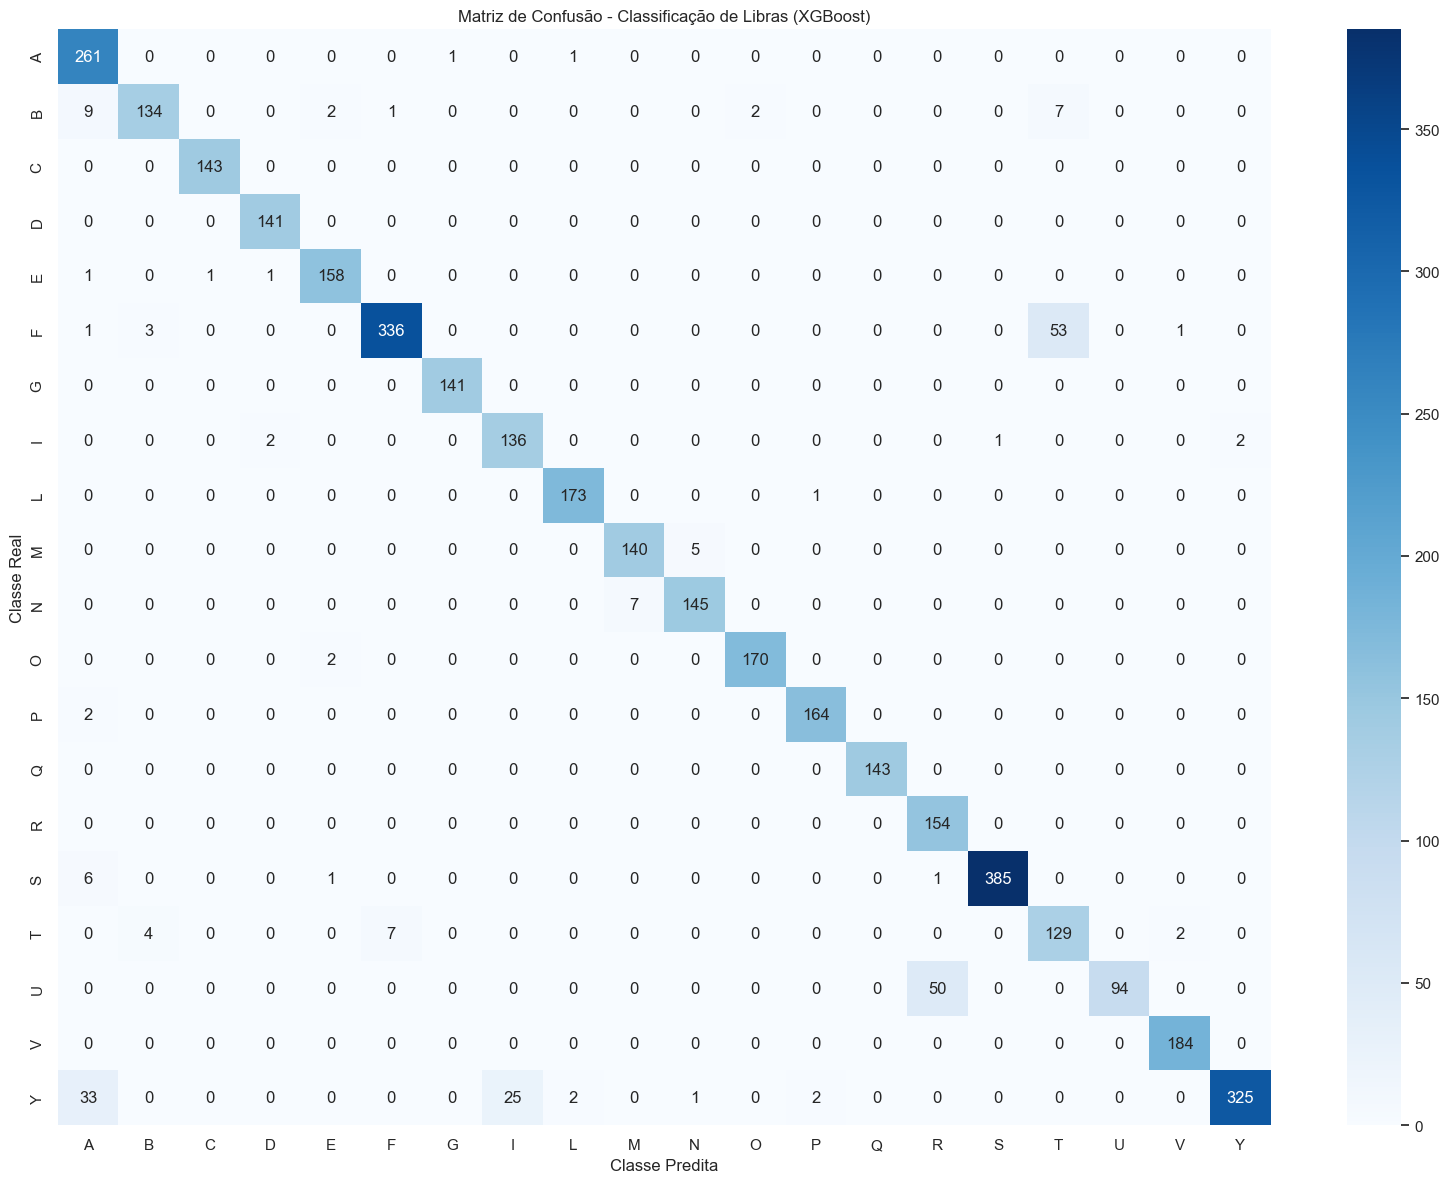

In [20]:
# Computando a matriz de confusão clássica
cm = confusion_matrix(y_val, y_pred, labels=unique_classes)

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=unique_classes,
    yticklabels=unique_classes,
)
plt.title("Matriz de Confusão - Classificação de Libras (XGBoost)")
plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")
plt.tight_layout()
plt.show()

## 6. Salvando o Artefato Final do Modelo

Com a validação validada e consolidada, exportamos o objeto do classificador treinado e o dicionário de mapeamento de índices para arquivos físicos indexados na pasta `models/`, viabilizando o carregamento imediato no script de teste oficial.

In [21]:
model_path = MODEL_OUTPUT / "xgb_libras_model.joblib"
joblib.dump(xgb_model, model_path)

mapping_data = {
    "class_to_idx": class_to_idx,
    "idx_to_class": {int(k): v for k, v in idx_to_class.items()},
    "feature_columns": feature_columns,
}

with open(MODEL_OUTPUT / "model_mapping.json", "w", encoding="utf-8") as f:
    json.dump(mapping_data, f, indent=2, ensure_ascii=False)

print(f"Artefatos exportados para: {MODEL_OUTPUT.resolve()}")

Artefatos exportados para: C:\Users\Bárbara\Documents\CortechX\LibrasQuest\model\models
